# Following dirty money

**Track:** AI + Finance · Veritas AI International High School Hackathon 2026

A compliance analyst at a crypto exchange can review only a few dozen transactions a day. I rank Bitcoin transactions by
how likely they are to be laundered money, test the ranking on future weeks the models never saw, and then ask the question
most tutorials skip: **what happens when criminals change their behaviour, and how fast can anyone notice?**

> This project is a prototype and is not financial advice.

Runs top to bottom on Google Colab; a GPU helps but is not needed. The data is public and downloads automatically, no API keys.

In [1]:
import importlib.util
import subprocess
import sys

if not importlib.util.find_spec("torch_geometric"):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torch_geometric"], check=True)

import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.sparse import coo_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch_geometric.nn import GATConv, GCNConv, SAGEConv
from torch_geometric.utils import to_undirected

DATA, FIG, RES, ART = map(Path, ["data", "figures", "results", "artifacts"])
for folder in (DATA, FIG, RES, ART):
    folder.mkdir(exist_ok=True)

SEED, TRAIN_END, BREAK = 42, 34, 43
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.titlesize": 9, "legend.fontsize": 8})


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png")
    plt.show()


print("running on", DEVICE)

running on cuda


## 1. Data: the Elliptic Bitcoin dataset

203,769 real Bitcoin transactions (nodes) and 234,355 payment flows between them (edges), in 49 time steps about two weeks
apart. Elliptic labelled 4,545 transactions **illicit** (scams, ransomware, dark markets, Ponzi schemes) and 42,019 **licit**
(exchanges, wallets, miners); the other 77% are unknown. Each transaction has 165 anonymised features: 93 about the
transaction itself and 72 summarising its neighbours. I standardise them with statistics from the training period only.

Source: Weber et al., *Anti-Money Laundering in Bitcoin* (KDD 2019 workshop), mirrored by PyTorch Geometric.

In [2]:
URL = "https://data.pyg.org/datasets/elliptic"
for name in ["elliptic_txs_features", "elliptic_txs_edgelist", "elliptic_txs_classes"]:
    if not (DATA / f"{name}.csv").exists():
        archive, _ = urllib.request.urlretrieve(f"{URL}/{name}.csv.zip", DATA / f"{name}.csv.zip")
        with zipfile.ZipFile(archive) as zipped:
            zipped.extractall(DATA)
        Path(archive).unlink()

features = pd.read_csv(DATA / "elliptic_txs_features.csv", header=None)
classes = pd.read_csv(DATA / "elliptic_txs_classes.csv", index_col="txId", dtype={"class": str})["class"]
edges = pd.read_csv(DATA / "elliptic_txs_edgelist.csv")

tx_ids, t = features[0].to_numpy(), features[1].to_numpy()
y = features[0].map(classes.map({"1": 1, "2": 0, "unknown": -1})).to_numpy()
row = pd.Series(np.arange(len(tx_ids)), index=tx_ids)
src, dst = row.loc[edges.txId1].to_numpy(), row.loc[edges.txId2].to_numpy()

raw = features.iloc[:, 2:].to_numpy(np.float32)
X = StandardScaler().fit(raw[t <= TRAIN_END]).transform(raw).astype(np.float32)
N_LOCAL = 93

print(f"{len(y):,} transactions, {len(src):,} payment flows, {X.shape[1]} features")
print(f"illicit {np.sum(y == 1):,} · licit {np.sum(y == 0):,} · unknown {np.sum(y == -1):,}")
print("flows between different time steps:", np.sum(t[src] != t[dst]))

203,769 transactions, 234,355 payment flows, 165 features
illicit 4,545 · licit 42,019 · unknown 157,205
flows between different time steps: 0


No flow crosses time steps, so every step is its own island of transactions. Training on early steps and testing on later
ones cannot leak information through the graph. Around step 43 a large dark market was shut down, and illicit activity changes.

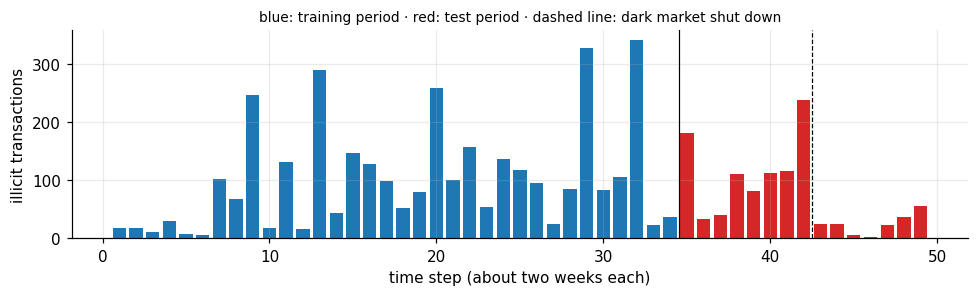

In [3]:
illicit = pd.Series(t[y == 1]).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.bar(illicit.index, illicit, color=np.where(illicit.index <= TRAIN_END, "C0", "C3"))
ax.axvline(TRAIN_END + 0.5, color="k", lw=0.8)
ax.axvline(BREAK - 0.5, color="k", lw=0.8, ls="--")
ax.set(xlabel="time step (about two weeks each)", ylabel="illicit transactions",
       title="blue: training period · red: test period · dashed line: dark market shut down")
save("illicit_per_step")

## 2. An honest split and the right metrics

* **Train:** steps 1-34. **Test:** steps 35-49, the future, never shuffled in.
* To choose how long the neural networks train I hold out steps 30-34 (validation) while training on 1-29, then refit on 1-34.
* Only about 10% of labelled transactions are illicit, so accuracy is misleading. I report **precision, recall and F1 for the
  illicit class** and the area under the precision-recall curve (PR-AUC).
* Every model except the two simplest baselines is trained with three random seeds. I average their predictions and report
  how much F1 varies between seeds.

In [4]:
labelled = y >= 0
train_mask, test_mask = labelled & (t <= TRAIN_END), labelled & (t > TRAIN_END)
fit_mask, val_mask = labelled & (t < 30), labelled & (t >= 30) & (t <= TRAIN_END)
TEST_STEPS = np.arange(TRAIN_END + 1, 50)
step_masks = {step: test_mask & (t == step) for step in TEST_STEPS}


def scores(mask, p):
    truth, guess = y[mask], p[mask] >= 0.5
    return {"precision": precision_score(truth, guess, zero_division=0),
            "recall": recall_score(truth, guess, zero_division=0),
            "f1": f1_score(truth, guess, zero_division=0),
            "pr_auc": average_precision_score(truth, p[mask])}


probs, seed_f1 = {}, {}


def record(name, runs):
    probs[name] = np.mean(runs, axis=0)
    seed_f1[name] = [scores(test_mask, p)["f1"] for p in runs]


print(f"train {train_mask.sum():,} · test {test_mask.sum():,} · illicit in test {y[test_mask].mean():.1%}")

train 29,894 · test 16,670 · illicit in test 6.5%


## 3. Baselines

1. **Always "licit"**: the laziest possible model. High accuracy, catches nothing.
2. **Logistic regression** on all features.
3. **Random forest** with 50 trees and 50 features per split, as in the original paper, where it beat their graph neural network.

In [5]:
def forest(mask, features=X, seed=SEED):
    model = RandomForestClassifier(n_estimators=50, max_features=50, n_jobs=-1, random_state=seed)
    return model.fit(features[mask], y[mask])


record("Always 'licit'", [np.zeros(len(y))])
logistic = LogisticRegression(max_iter=3000).fit(X[train_mask], y[train_mask])
record("Logistic regression", [logistic.predict_proba(X)[:, 1]])
forests = [forest(train_mask, seed=SEED + s) for s in range(3)]
record("Random forest", [f.predict_proba(X)[:, 1] for f in forests])

## 4. Graph neural networks

Launderers rarely act alone: dirty coins hop through chains of transactions. A graph neural network lets every transaction
look at the transactions it pays and is paid by. Three common designs, plus an **MLP** with the same layers that cannot see
the graph:

* **GCN** averages its neighbours' information (Kipf & Welling 2017).
* **GraphSAGE** keeps its own features apart from its neighbours' (Hamilton et al. 2017).
* **GAT** learns how much attention to pay to each neighbour (Veličković et al. 2018).

Each has two layers with 100 hidden units and a class-weighted loss (illicit 0.7, licit 0.3, as in the paper), trained on
the whole graph at once. Unknown transactions pass messages but never enter the loss.

In [6]:
class Dense(nn.Linear):
    def forward(self, x, edge_index):
        return super().forward(x)


CONVS = {"MLP": Dense, "GCN": GCNConv, "GraphSAGE": SAGEConv, "GAT": GATConv}


class Net(nn.Module):
    def __init__(self, conv, hidden=100):
        super().__init__()
        self.conv1, self.conv2 = conv(X.shape[1], hidden), conv(hidden, 2)

    def embed(self, x):
        return F.relu(self.conv1(x, edge_index))

    def forward(self, x):
        return self.conv2(F.dropout(self.embed(x), 0.3, self.training), edge_index)


x_all = torch.tensor(X, device=DEVICE)
y_all = torch.tensor(np.maximum(y, 0), device=DEVICE)
edge_index = to_undirected(torch.tensor(np.vstack([src, dst]), device=DEVICE))
class_weight = torch.tensor([0.3, 0.7], device=DEVICE)


@torch.no_grad()
def predict(model):
    model.eval()
    return model(x_all).softmax(1)[:, 1].cpu().numpy()


def train(conv, mask, epochs, seed, watch=None):
    torch.manual_seed(seed)
    model = Net(conv).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    mask, curve = torch.tensor(mask, device=DEVICE), []
    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        F.cross_entropy(model(x_all)[mask], y_all[mask], weight=class_weight).backward()
        optimizer.step()
        if watch is not None and epoch % 10 == 0:
            curve.append(scores(watch, predict(model))["f1"])
    return model, curve

**How long to train.** Each network trains on steps 1-29 while I watch F1 on steps 30-34 every 10 epochs. The best epoch
count is then used to refit on steps 1-34 with three seeds.

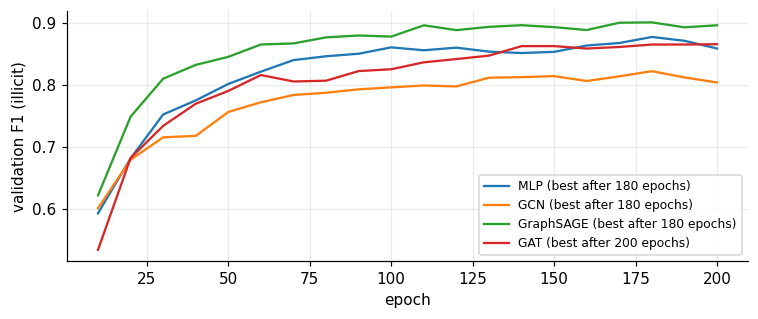

In [7]:
MAX_EPOCHS = 200
best_epochs, val_f1, nets = {}, {}, {}

fig, ax = plt.subplots(figsize=(7, 3))
for name, conv in CONVS.items():
    _, curve = train(conv, fit_mask, MAX_EPOCHS, SEED, watch=val_mask)
    best_epochs[name], val_f1[name] = 10 * (int(np.argmax(curve)) + 1), max(curve)
    ax.plot(range(10, MAX_EPOCHS + 1, 10), curve, label=f"{name} (best after {best_epochs[name]} epochs)")
ax.set(xlabel="epoch", ylabel="validation F1 (illicit)")
ax.legend()
save("validation_curves")

for name, conv in CONVS.items():
    models = [train(conv, train_mask, best_epochs[name], SEED + s)[0] for s in range(3)]
    record(name, [predict(model) for model in models])
    nets[name] = models[0]

## 5. Hybrid: random forest + graph embeddings

Trees are great with raw features; graph networks are great at reading neighbourhoods. The paper's best model gave a random
forest the network's hidden layer, a 100-number summary of each transaction's neighbourhood. I do the same with the graph
network that scored best on validation. This hybrid is the model I deploy for the rest of the notebook.

In [8]:
best_gnn = max(["GCN", "GraphSAGE", "GAT"], key=val_f1.get)
DEPLOYED = f"RF + {best_gnn} embeddings"

with torch.no_grad():
    X_hybrid = np.hstack([X, nets[best_gnn].embed(x_all).cpu().numpy()])
hybrids = [forest(train_mask, X_hybrid, SEED + s) for s in range(3)]
record(DEPLOYED, [h.predict_proba(X_hybrid)[:, 1] for h in hybrids])
print("best graph network on validation:", best_gnn)

best graph network on validation: GraphSAGE


## 6. Results on the unseen future (steps 35-49)

In [9]:
def summary(name):
    result = {metric: round(value, 3) for metric, value in scores(test_mask, probs[name]).items()}
    f1s = seed_f1[name]
    result["F1 per seed"] = f"{np.mean(f1s):.3f} ± {np.std(f1s):.3f}" if len(f1s) > 1 else ""
    return result


table = pd.DataFrame({name: summary(name) for name in probs}).T
table.to_csv(RES / "test_results.csv")
table

,precision,recall,f1,pr_auc,F1 per seed
Always 'licit',0.0,0.0,0.0,0.065,
Logistic regression,0.318,0.705,0.438,0.328,
Random forest,0.917,0.723,0.808,0.782,0.802 ± 0.001
MLP,0.611,0.558,0.583,0.545,0.586 ± 0.009
GCN,0.789,0.498,0.61,0.634,0.601 ± 0.028
GraphSAGE,0.708,0.596,0.648,0.682,0.643 ± 0.023
GAT,0.681,0.416,0.517,0.57,0.520 ± 0.043
RF + GraphSAGE embeddings,0.972,0.716,0.824,0.784,0.819 ± 0.001


## 7. Week by week: the day the dark market closed

One number for the whole test period hides the most important event in the data. Around step 43 a large dark market was
shut down, criminals moved money differently, and models trained on the old patterns stopped finding them.

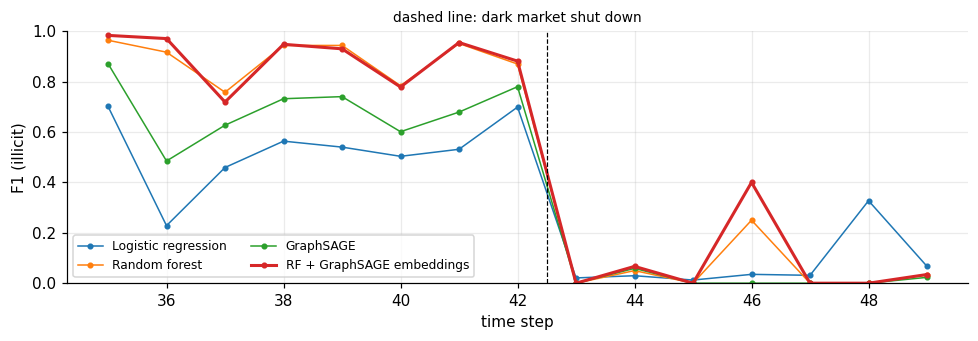

,steps 35-42,steps 43-49
Logistic regression,0.528,0.075
Random forest,0.891,0.048
MLP,0.595,0.011
GCN,0.623,0.075
GraphSAGE,0.689,0.012
GAT,0.509,0.000
RF + GraphSAGE embeddings,0.896,0.072


In [10]:
risk = probs[DEPLOYED]
step_f1 = pd.DataFrame({name: [scores(m, probs[name])["f1"] for m in step_masks.values()]
                        for name in probs if name != "Always 'licit'"}, index=TEST_STEPS)
step_f1.to_csv(RES / "f1_per_step.csv")

fig, ax = plt.subplots(figsize=(9, 3.2))
for name in ["Logistic regression", "Random forest", best_gnn, DEPLOYED]:
    ax.plot(TEST_STEPS, step_f1[name], marker="o", ms=3, lw=2 if name == DEPLOYED else 1, label=name)
ax.axvline(BREAK - 0.5, color="k", ls="--", lw=0.8)
ax.set(xlabel="time step", ylabel="F1 (illicit)", ylim=(0, 1), title="dashed line: dark market shut down")
ax.legend(ncol=2, loc="lower left")
save("f1_per_step")

pd.DataFrame({"steps 35-42": step_f1.loc[:BREAK - 1].mean(), "steps 43-49": step_f1.loc[BREAK:].mean()}).round(3)

## 8. What it means for an analyst: a review budget

The analyst can check only **K transactions per time step**. The useful question is not "what is the F1?" but "if I review
the K riskiest transactions, how many launderers do I find?" The baseline is reviewing K transactions at random.

In [11]:
def found(p, k):
    return sum(int(y[m][np.argsort(-p[m])[:k]].sum()) for m in step_masks.values())


budget = pd.DataFrame(index=pd.Index([20, 50, 100], name="reviews per step"))
budget["random reviews"] = [round(sum(k * y[m].mean() for m in step_masks.values())) for k in budget.index]
for name in step_f1:
    budget[name] = [found(probs[name], k) for k in budget.index]
budget.to_csv(RES / "review_budget.csv")

print(f"illicit transactions in the test period: {y[test_mask].sum():,}")
budget

illicit transactions in the test period: 1,083


,random reviews,Logistic regression,Random forest,MLP,GCN,GraphSAGE,GAT,RF + GraphSAGE embeddings
reviews per step,,,,,,,,
20,20,61,163,130,143,155,131,168
50,51,181,367,290,339,358,292,376
100,102,457,645,523,575,591,527,652


## 9. Can anyone tell that the model broke?

Confirmed labels come from investigations and arrive months later; a team that waits for them keeps trusting a broken model.
I test three monitors, checked every time step, from no labels to very few:

1. **Flag rate** (no labels): the share of never-labelled transactions the model flags as illicit.
2. **Data drift** (no labels): how well a simple classifier tells this step's transactions apart from the previous three
   steps (ROC-AUC: 0.5 means "looks the same", 1.0 "completely different"). Comparing with the whole training period is
   useless, because every new step looks different from the distant past.
3. **Analyst hit rate** (10 labels per step): the analyst reviews the 10 riskiest transactions anyway. What share turn out
   to be laundering? Those answers arrive within days. I can only check against Elliptic's labels, so the analyst
   "reviews" the 10 riskiest labelled transactions.

In [12]:
unlabelled = y == -1
WATCHED = np.arange(4, 50)


def sample(mask, n=2000):
    candidates = np.flatnonzero(mask)
    return rng.choice(candidates, min(n, len(candidates)), replace=False)


def flag_rate(step):
    return np.mean(risk[unlabelled & (t == step)] >= 0.5)


def drift(step):
    now, before = sample(t == step), sample((t >= step - 3) & (t < step))
    data = np.vstack([X[now, :N_LOCAL], X[before, :N_LOCAL]])
    is_now = np.r_[np.ones(len(now)), np.zeros(len(before))]
    return cross_val_score(LogisticRegression(max_iter=1000), data, is_now, cv=3, scoring="roc_auc").mean()


def hit_rate(step, k=10):
    m = labelled & (t == step)
    return y[m][np.argsort(-risk[m])[:k]].mean()


monitor = pd.DataFrame({
    "flag rate": [flag_rate(step) for step in WATCHED],
    "drift AUC": [drift(step) for step in WATCHED],
    "analyst hit rate": [hit_rate(step) if step > TRAIN_END else np.nan for step in WATCHED],
    "true F1": [scores(labelled & (t == step), risk)["f1"] if step > TRAIN_END else np.nan for step in WATCHED],
}, index=WATCHED)
monitor.loc[TRAIN_END + 1:].round(3)

,flag rate,drift AUC,analyst hit rate,true F1
35,0.072,0.685,1.0,0.983
36,0.070,0.672,1.0,0.971
37,0.039,0.598,1.0,0.719
38,0.088,0.615,1.0,0.948
39,0.130,0.729,1.0,0.930
40,0.092,0.650,1.0,0.778
41,0.092,0.618,1.0,0.955
42,0.094,0.604,1.0,0.881
43,0.057,0.641,0.0,0.000
44,0.103,0.760,0.1,0.067


The alarm rules are fixed before looking at the test period. Flag rate and drift alarm when they leave their usual range in
the training period (median ± 3 × MAD, a robust version of mean ± 3 standard deviations). The hit-rate alarm fires when
fewer than half of the 10 reviews confirm laundering.

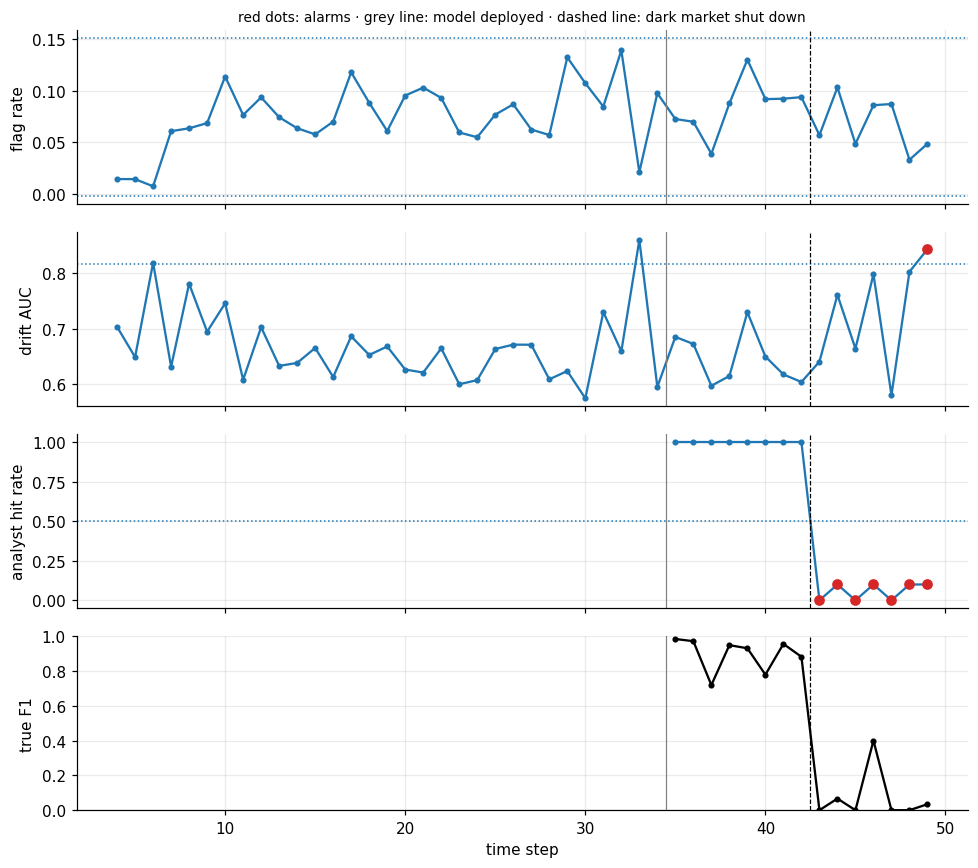

,false alarms while the model worked (35-42),first alarm after the break,alarms during the break (43-49)
flag rate,0,none,0 of 7
drift AUC,0,49,1 of 7
analyst hit rate,0,43,7 of 7


In [13]:
def usual_range(signal):
    reference = signal.loc[:TRAIN_END]
    spread = 3 * 1.4826 * (reference - reference.median()).abs().median()
    return reference.median() - spread, reference.median() + spread


flag_low, flag_high = usual_range(monitor["flag rate"])
drift_high = usual_range(monitor["drift AUC"])[1]
limits = {"flag rate": (flag_low, flag_high), "drift AUC": (drift_high,), "analyst hit rate": (0.5,)}
alarms = pd.DataFrame({
    "flag rate": ~monitor["flag rate"].between(flag_low, flag_high),
    "drift AUC": monitor["drift AUC"] > drift_high,
    "analyst hit rate": monitor["analyst hit rate"] < 0.5,
}).loc[TRAIN_END + 1:]
monitor.join(alarms.add_suffix(" alarm")).to_csv(RES / "monitor.csv")

fig, axes = plt.subplots(4, 1, figsize=(9, 8), sharex=True)
for ax, signal in zip(axes, monitor):
    ax.plot(monitor.index, monitor[signal], marker="o", ms=3, color="k" if signal == "true F1" else "C0")
    for level in limits.get(signal, ()):
        ax.axhline(level, color="C0", ls=":", lw=1)
    if signal in alarms:
        fired = alarms.index[alarms[signal]]
        ax.scatter(fired, monitor.loc[fired, signal], color="C3", zorder=3)
    ax.axvline(TRAIN_END + 0.5, color="grey", lw=0.8)
    ax.axvline(BREAK - 0.5, color="k", ls="--", lw=0.8)
    ax.set_ylabel(signal)
axes[0].set_title("red dots: alarms · grey line: model deployed · dashed line: dark market shut down")
axes[-1].set(xlabel="time step", ylim=(0, 1))
save("monitor")


def report(fired):
    after = fired.loc[BREAK:]
    return {"false alarms while the model worked (35-42)": int(fired.loc[:BREAK - 1].sum()),
            "first alarm after the break": after.idxmax() if after.any() else "none",
            "alarms during the break (43-49)": f"{after.sum()} of {len(after)}"}


alarm_summary = pd.DataFrame({signal: report(alarms[signal]) for signal in alarms}).T
alarm_summary.to_csv(RES / "alarm_summary.csv")
alarm_summary

## 10. When the alarm rings: does retraining fix it?

Suppose the team retrains the random forest every time step on all labels it has so far. Labels arrive late, so I try a
**1-step delay** (about two weeks, optimistic) and a **4-step delay** (about two months, realistic).

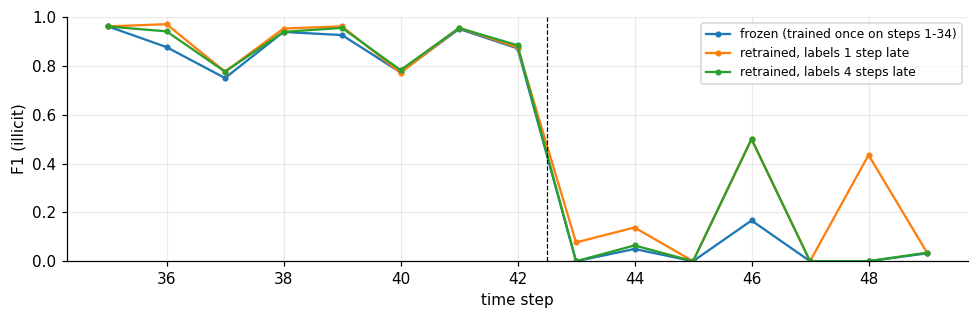

,steps 35-42,steps 43-49
frozen (trained once on steps 1-34),0.881,0.036
"retrained, labels 1 step late",0.903,0.169
"retrained, labels 4 steps late",0.899,0.086


In [14]:
def forest_f1_per_step(delay=None):
    f1s = []
    for step, m in step_masks.items():
        model = forests[0] if delay is None else forest(labelled & (t <= step - delay))
        f1s.append(f1_score(y[m], model.predict_proba(X[m])[:, 1] >= 0.5, zero_division=0))
    return f1s


retrain = pd.DataFrame({"frozen (trained once on steps 1-34)": forest_f1_per_step(),
                        "retrained, labels 1 step late": forest_f1_per_step(1),
                        "retrained, labels 4 steps late": forest_f1_per_step(4)}, index=TEST_STEPS)
retrain.to_csv(RES / "retraining.csv")

ax = retrain.plot(marker="o", ms=3, figsize=(9, 3), ylim=(0, 1), xlabel="time step", ylabel="F1 (illicit)")
ax.axvline(BREAK - 0.5, color="k", ls="--", lw=0.8)
save("retraining")

pd.DataFrame({"steps 35-42": retrain.loc[:BREAK - 1].mean(), "steps 43-49": retrain.loc[BREAK:].mean()}).round(3)

## 11. Why was this transaction flagged?

An analyst will not freeze money because "the model said so". For each transaction I show what they can check: its risk,
its neighbourhood in the payment graph, and the features where it looks least like normal (licit) activity, measured in
standard deviations on the 30 features the random forest relies on most. Elliptic anonymised the features, so I can only
name them by number.

transaction 70335041 at time step 35, truly illicit: {'risk': 0.947, 'linked transactions': 2, 'risky linked transactions': 2, 'least normal features (SD)': {'neighbour feature 10': 2.0, 'tx feature 53': -1.1, 'tx feature 55': -1.0}}


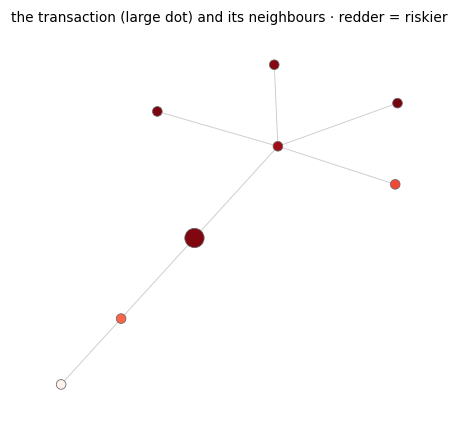

In [15]:
FEATURE_NAMES = ([f"tx feature {i}" for i in range(1, N_LOCAL + 1)]
                 + [f"neighbour feature {i}" for i in range(1, X.shape[1] - N_LOCAL + 1)])
top = np.argsort(-forests[0].feature_importances_)[:30]
licit = X[train_mask & (y == 0)][:, top]
z = (X[:, top] - licit.mean(0)) / licit.std(0)
adjacency = coo_matrix((np.ones(2 * len(src)), (np.r_[src, dst], np.r_[dst, src])), shape=(len(y), len(y))).tocsr()


def neighbours(i):
    return adjacency[i].indices


def explain(i):
    near = neighbours(i)
    strongest = np.argsort(-np.abs(z[i]))[:3]
    return {"risk": round(float(risk[i]), 3),
            "linked transactions": len(near),
            "risky linked transactions": int(np.sum(risk[near] >= 0.5)),
            "least normal features (SD)": {FEATURE_NAMES[top[k]]: round(float(z[i, k]), 1) for k in strongest}}


def draw(i, ax):
    first = neighbours(i)[:40]
    graph = nx.Graph([(i, j) for j in first] + [(j, k) for j in first for k in neighbours(j)[:5] if k != i])
    nx.draw_networkx(graph, nx.spring_layout(graph, seed=SEED), ax=ax, with_labels=False,
                     node_color=[risk[n] for n in graph], cmap="Reds", vmin=0, vmax=1,
                     node_size=[160 if n == i else 40 for n in graph], edgecolors="#666", linewidths=0.5,
                     edge_color="#ccc", width=0.6)
    ax.set_axis_off()


example = max(np.flatnonzero(test_mask & (y == 1) & (risk >= 0.9)), key=lambda i: np.sum(risk[neighbours(i)] >= 0.5))
print(f"transaction {tx_ids[example]} at time step {t[example]}, truly illicit:", explain(example))

fig, ax = plt.subplots(figsize=(4, 4))
draw(example, ax)
ax.set_title("the transaction (large dot) and its neighbours · redder = riskier")
save("explain_example")

## 12. Where it fails, and why

After step 43 the model misses nearly everything (sections 7 and 9). But even in good weeks it misses some launderers.
Here is how they differ from the ones it catches.

In [16]:
good_weeks = (t > TRAIN_END) & (t < BREAK)
groups = {"caught launderers": np.flatnonzero(good_weeks & (y == 1) & (risk >= 0.5)),
          "missed launderers": np.flatnonzero(good_weeks & (y == 1) & (risk < 0.5)),
          "licit transactions": np.flatnonzero(good_weeks & (y == 0))}
failure = pd.DataFrame({
    "count": [len(idx) for idx in groups.values()],
    "linked to a risky transaction": [np.mean([np.any(risk[neighbours(i)] >= 0.5) for i in idx])
                                      for idx in groups.values()],
    "distance from normal activity (SD)": [np.abs(z[idx]).mean() for idx in groups.values()],
}, index=list(groups)).round(2)

misses = groups["missed launderers"]
worst = misses[np.argmin(risk[misses])]
print(f"near misses (risk 20-50%): {np.sum(risk[misses] >= 0.2)} of {len(misses)}")
print(f"most confident miss: transaction {tx_ids[worst]} at time step {t[worst]}:", explain(worst))
failure

near misses (risk 20-50%): 37 of 142
most confident miss: transaction 28878820 at time step 37: {'risk': 0.007, 'linked transactions': 1, 'risky linked transactions': 0, 'least normal features (SD)': {'neighbour feature 10': 2.1, 'tx feature 53': -0.9, 'tx feature 90': -0.9}}


,count,linked to a risky transaction,distance from normal activity (SD)
caught launderers,772,0.34,0.46
missed launderers,142,0.09,0.45
licit transactions,9069,0.10,0.59


**Why it misses them.** Look at their company. A third of the launderers the model catches are linked to a transaction it
finds risky; of the ones it misses, only 9% are, about the same as licit transactions (10%). Feature by feature, missed and
caught launderers are equally unremarkable (0.45 and 0.46 standard deviations from normal activity). What gives laundering
away is a combination of features plus risky neighbours, and the missed ones have neither: they look ordinary and keep
ordinary company. 37 of the 142 are near misses that a lower threshold would catch, at the price of freezing more innocent
users' money.

## 13. Save what the demo app needs

In [17]:
models = {name: p for name, p in probs.items() if name != "Always 'licit'"}
np.savez_compressed(ART / "app_data.npz", tx_ids=tx_ids, t=t, y=y, src=src, dst=dst,
                    model_names=np.array(list(models)), model_risk=np.array(list(models.values()), dtype=np.float16),
                    deployed=np.array(DEPLOYED), limits=np.array([flag_low, flag_high, drift_high]))

## Takeaways

1. **The graph helps, trees still win.** GraphSAGE beats the same network without the graph (F1 0.65 vs 0.58), but the best
   model is a random forest fed with GraphSAGE's neighbourhood summaries: **F1 0.82**, and 97% of its flags are truly illicit.
2. **For an analyst with 50 reviews per time step** it finds 376 of 1,083 illicit transactions, about 7× more than reviewing
   at random.
3. **When the dark market closed, every model broke, silently.** F1 fell from 0.90 to 0.07 while the model kept flagging the
   same share of transactions. The label-free monitors missed it: the flag rate never alarmed, and the drift test alarmed
   once, six steps late.
4. **The reliable alarm was the analyst's own hit rate.** If fewer than 5 of the 10 riskiest transactions they check turn out
   to be laundering, stop trusting the model. It fired at step 43, at every step after, and never before.
5. **Retraining barely helps after the break** (F1 0.04 → 0.17 even with labels only one step late), because the new
   behaviour has almost no examples yet. Monitoring tells you when to bring in human investigators; it cannot replace them.